# NSE Futures Strategy — Research Notebook

Cross-sectional momentum + mean-reversion on NSE F&O futures universe.

**Strategy logic**
- Universe: NSE F&O stocks (top ~30 by liquidity) + NIFTY / BANKNIFTY index futures
- Signal: 3-month cross-sectional momentum ranking → long top decile, short bottom decile
- Entry filter: RSI(2) < 10 (longs) or > 90 (shorts), price near lower/upper Bollinger Band
- Sizing: ATR-based risk targeting (1% NAV per trade), capped by margin / exposure limits
- Exit: ATR stop (2×ATR), RSI mean-reversion target, or 5-day time stop
- Costs: Zerodha F&O rates (₹20 flat + STT 0.0125% sell-side + exchange/SEBI/GST/slippage)
- Regime filter: India VIX scalar — reduce / pause positions in high-vol regimes

In [7]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 130
matplotlib.rcParams['figure.figsize'] = (12, 5)

print('Imports OK')

Imports OK


## 1. Load Universe

In [8]:
from strategy.universe import DEFAULT_UNIVERSE, LOT_SIZES, INDEX_FUTURES

print(f'Total universe size: {len(DEFAULT_UNIVERSE)}')
print(f'Index futures: {INDEX_FUTURES}')
print(f'Stock futures: {[t for t in DEFAULT_UNIVERSE if t not in INDEX_FUTURES]}')

Total universe size: 32
Index futures: ['NIFTY', 'BANKNIFTY']
Stock futures: ['RELIANCE', 'HDFCBANK', 'ICICIBANK', 'INFY', 'TCS', 'SBIN', 'AXISBANK', 'WIPRO', 'BAJFINANCE', 'KOTAKBANK', 'LT', 'MARUTI', 'TATAMOTORS', 'HCLTECH', 'SUNPHARMA', 'TITAN', 'BHARTIARTL', 'ADANIENT', 'NTPC', 'ONGC', 'JSWSTEEL', 'HINDALCO', 'DRREDDY', 'CIPLA', 'TECHM', 'BAJAJ-AUTO', 'GRASIM', 'ASIANPAINT', 'INDUSINDBK', 'HINDUNILVR']


## 2. Download Data

In [9]:
from strategy.data import load_futures_dataset

START = '2018-01-01'
END   = '2024-12-31'

dataset = load_futures_dataset(
    tickers=DEFAULT_UNIVERSE,
    start=START,
    end=END,
    data_dir='../data/cache',
)

futures_close = dataset['futures']['close']
india_vix     = dataset['india_vix']

print(f"Dates:   {futures_close.index[0].date()} → {futures_close.index[-1].date()}")
print(f"Tickers: {list(futures_close.columns)}")
print(f"NaN pct per column:\n{futures_close.isna().mean().sort_values(ascending=False).head(10)}")

[DATA] Loading spot cache → ../data/cache/spot_2018-01-01_2024-12-31.pkl
[DATA] Dropped 1 tickers due to missing data: {'TATAMOTORS'}
Dates:   2018-01-01 → 2024-12-30
Tickers: ['ADANIENT', 'ASIANPAINT', 'AXISBANK', 'BAJAJ-AUTO', 'BAJFINANCE', 'BHARTIARTL', 'CIPLA', 'DRREDDY', 'GRASIM', 'HCLTECH', 'HDFCBANK', 'HINDALCO', 'HINDUNILVR', 'ICICIBANK', 'INDUSINDBK', 'INFY', 'JSWSTEEL', 'KOTAKBANK', 'LT', 'MARUTI', 'NTPC', 'ONGC', 'RELIANCE', 'SBIN', 'SUNPHARMA', 'TCS', 'TECHM', 'TITAN', 'WIPRO', 'BANKNIFTY', 'NIFTY']
NaN pct per column:
NIFTY        0.00058
JSWSTEEL     0.00000
BANKNIFTY    0.00000
WIPRO        0.00000
TITAN        0.00000
TECHM        0.00000
TCS          0.00000
SUNPHARMA    0.00000
SBIN         0.00000
RELIANCE     0.00000
dtype: float64


## 3. Synthetic Futures Prices

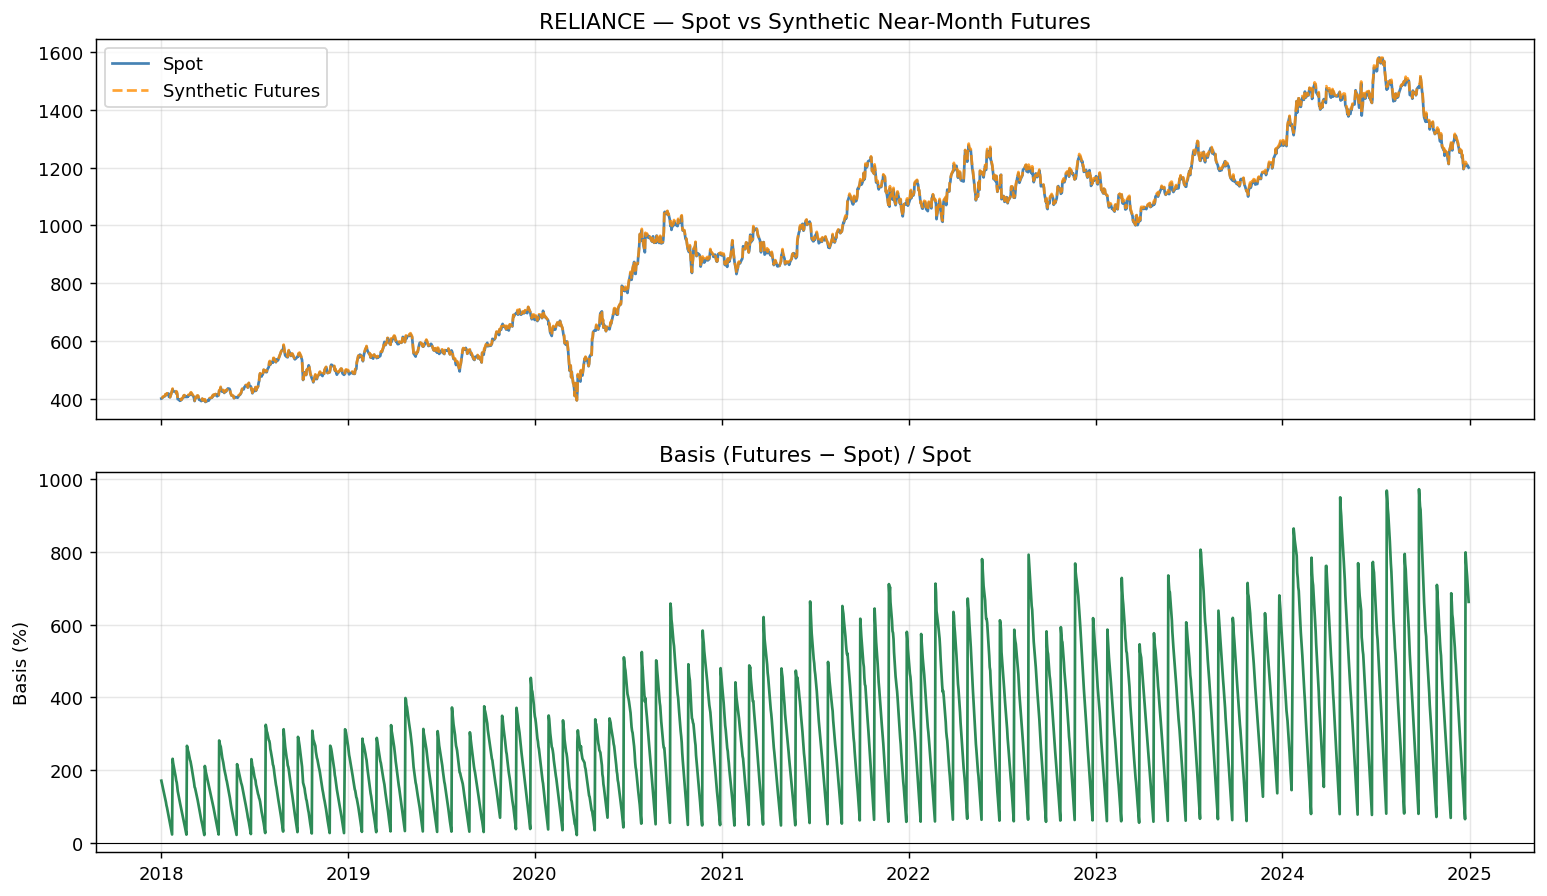

In [10]:
# Compare spot vs synthetic futures for a sample ticker
TICKER = 'RELIANCE'

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

spot_px = dataset['spot']['close'][TICKER].dropna()
fut_px  = futures_close[TICKER].dropna()

axes[0].plot(spot_px.index, spot_px, label='Spot', color='steelblue')
axes[0].plot(fut_px.index, fut_px, label='Synthetic Futures', color='darkorange', linestyle='--', alpha=0.8)
axes[0].set_title(f'{TICKER} — Spot vs Synthetic Near-Month Futures')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Basis (futures − spot)
from strategy.signals import calculate_basis
basis = calculate_basis(futures_close[[TICKER]], dataset['spot']['close'][[TICKER]])[TICKER].dropna()
axes[1].plot(basis.index, basis * 100, color='seagreen')
axes[1].axhline(0, color='black', lw=0.6)
axes[1].set_ylabel('Basis (%)')
axes[1].set_title('Basis (Futures − Spot) / Spot')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. India VIX Regime

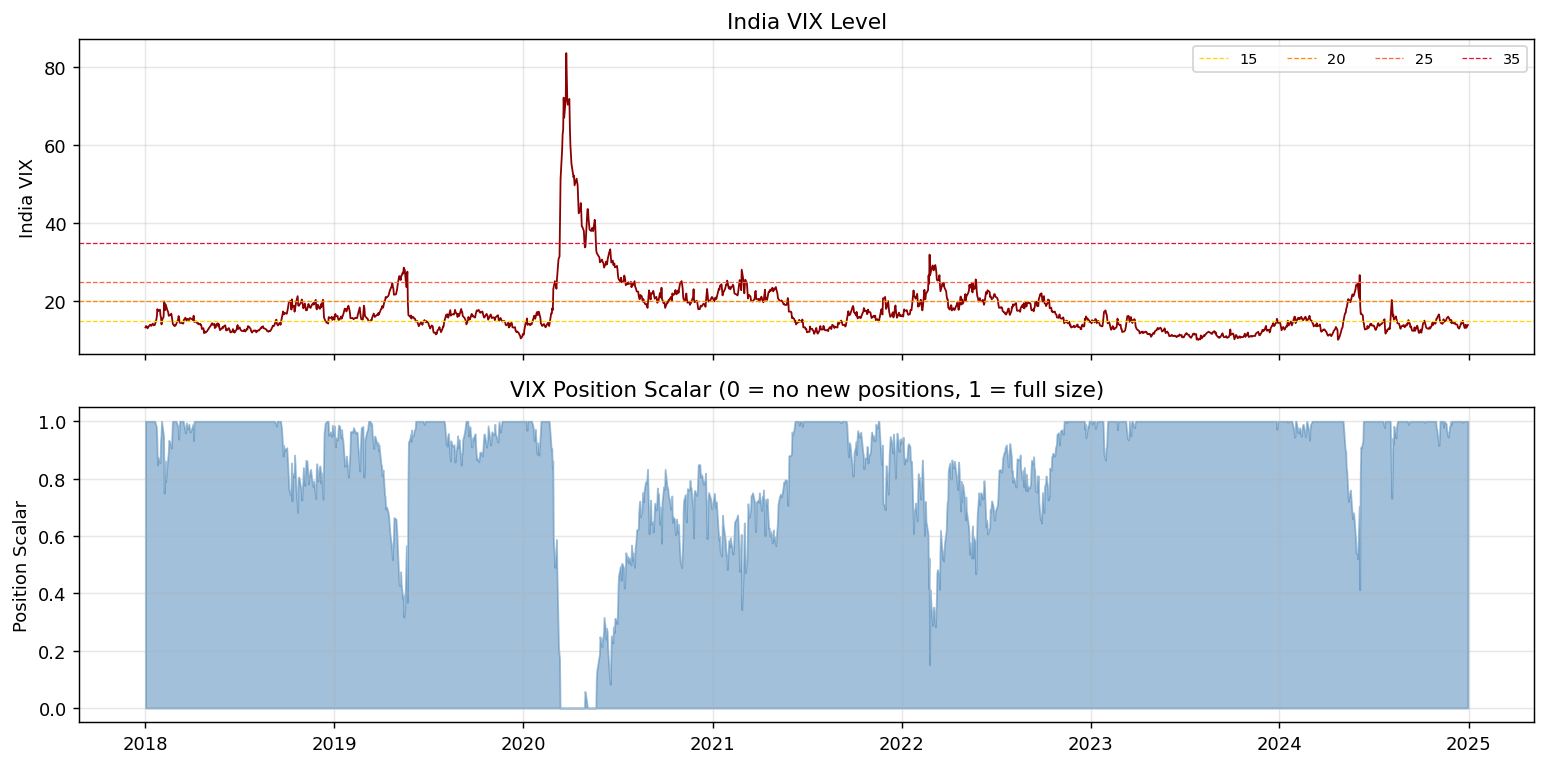

vix_regime
low_vol     725
normal      582
elevated    278
high_vol     82
extreme      43
Name: count, dtype: int64


In [11]:
from strategy.signals import india_vix_regime, vix_position_scalar

vix_label  = india_vix_regime(india_vix)
vix_scalar = vix_position_scalar(india_vix)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(india_vix.index, india_vix, color='darkred', lw=1)
axes[0].set_ylabel('India VIX')
axes[0].set_title('India VIX Level')
for level, color in [(15,'gold'), (20,'darkorange'), (25,'tomato'), (35,'crimson')]:
    axes[0].axhline(level, color=color, lw=0.7, linestyle='--', label=str(level))
axes[0].legend(fontsize=8, ncol=4)
axes[0].grid(alpha=0.3)

axes[1].fill_between(vix_scalar.index, vix_scalar, color='steelblue', alpha=0.5)
axes[1].set_ylabel('Position Scalar')
axes[1].set_title('VIX Position Scalar (0 = no new positions, 1 = full size)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(vix_label.value_counts())

## 5. Signals Inspection

In [12]:
from strategy.signals import (
    calculate_momentum, rank_momentum, get_long_candidates, get_short_candidates,
    calculate_rsi, calculate_bollinger_bands, calculate_sma, calculate_atr,
    get_entry_signals, detect_combined_regime,
)

close = futures_close
high  = dataset['futures']['high']
low   = dataset['futures']['low']

momentum = calculate_momentum(close, window=60)
ranks    = rank_momentum(momentum)
total    = len(close.columns)

long_c  = get_long_candidates(ranks,  top_n=10)
short_c = get_short_candidates(ranks, total_stocks=total, bottom_n=10)

rsi           = calculate_rsi(close, period=2)
bb_u, bb_m, bb_l = calculate_bollinger_bands(close, window=20)
ma50          = calculate_sma(close, window=50)
atr           = calculate_atr(high, low, close, period=14)

long_entries, short_entries = get_entry_signals(
    long_c, short_c, rsi, bb_u, bb_l, close, ma50
)

nifty_close = dataset['spot']['close']['NIFTY'] if 'NIFTY' in dataset['spot']['close'] else None
regime      = detect_combined_regime(nifty_close, india_vix)

print(f'Long entry signals per date:  {long_entries.sum(axis=1).mean():.2f} avg')
print(f'Short entry signals per date: {short_entries.sum(axis=1).mean():.2f} avg')
# print(f'Regime distribution:\n{regime["regime"].value_counts()}')

Long entry signals per date:  0.06 avg
Short entry signals per date: 0.05 avg


## 6. Transaction Costs Preview

In [13]:
from strategy.costs import compute_futures_cost, round_trip_cost_pct

# Example: 1 lot NIFTY at 22000  (lot size = 75)
nifty_notional = 1 * 75 * 22000
print(f'NIFTY 1-lot notional: ₹{nifty_notional:,.0f}')
buy  = compute_futures_cost(nifty_notional, 'BUY',  is_index=True)
sell = compute_futures_cost(nifty_notional, 'SELL', is_index=True)

print('\nBUY side costs:')
for k, v in buy.items(): print(f'  {k:<20}  ₹{v:.2f}')
print('\nSELL side costs:')
for k, v in sell.items(): print(f'  {k:<20}  ₹{v:.2f}')

rt = round_trip_cost_pct(is_index=True)
print(f'\nRound-trip cost (NIFTY): {rt*100:.4f}%')
print(f'Round-trip ₹ on 1 lot:  ₹{rt * nifty_notional:.2f}')

NIFTY 1-lot notional: ₹1,650,000

BUY side costs:
  brokerage             ₹20.00
  stt                   ₹0.00
  exchange              ₹28.55
  sebi                  ₹1.65
  gst                   ₹9.04
  stamp                 ₹33.00
  slippage              ₹330.00
  total                 ₹422.23

SELL side costs:
  brokerage             ₹20.00
  stt                   ₹206.25
  exchange              ₹28.55
  sebi                  ₹1.65
  gst                   ₹9.04
  stamp                 ₹0.00
  slippage              ₹330.00
  total                 ₹595.48

Round-trip cost (NIFTY): 0.0614%
Round-trip ₹ on 1 lot:  ₹1013.58


## 7. Run Backtest

In [14]:
from strategy.backtest import FuturesBacktestConfig, FuturesBacktestEngine

cfg = FuturesBacktestConfig(
    initial_capital      = 5_000_000.0,
    max_long             = 8,
    max_short            = 8,
    hold_days            = 5,
    risk_fraction        = 0.01,
    atr_stop_mult        = 2.0,
    max_gross_multiple   = 3.0,
    daily_loss_limit     = 0.03,
    max_drawdown_limit   = 0.20,
)

engine  = FuturesBacktestEngine(cfg)
results = engine.run(dataset, long_entries, short_entries, rsi, atr, regime)

print(f'Final NAV:   ₹{results["equity_curve"].iloc[-1]:,.0f}')
print(f'Total trades: {len(results["trade_log"])}')

Final NAV:   ₹5,043,052
Total trades: 29


## 8. Performance Report

In [15]:
from strategy.metrics import generate_performance_report

summary = generate_performance_report(
    equity          = results['equity_curve'],
    daily_returns   = results['daily_returns'],
    trade_log       = results['trade_log'],
    initial_capital = cfg.initial_capital,
    output_dir      = '../results',
)


  FUTURES STRATEGY — PERFORMANCE REPORT
  Start Date          2018-01-01
  End Date            2024-12-30
  Initial Capital     ₹5,000,000
  Final Nav           ₹5,043,052
  Total Return Pct    0.86%
  Cagr Pct            0.13%
  Volatility Ann      0.90%
  Sharpe              -6.828
  Sortino             -10.604
  Calmar              0.089
  Max Drawdown        -1.40%
  Total Trades        29
  Win Rate            58.6%
  Profit Factor       1.14
  Avg Win             ₹12,191
  Avg Loss            ₹-15,109
  Avg Hold Days       5.0
  Total Pnl           ₹25,942
  Total Costs         ₹22,508
  Rollover Costs      ₹5,070
  Years Simulated     7.0



## 9. Charts

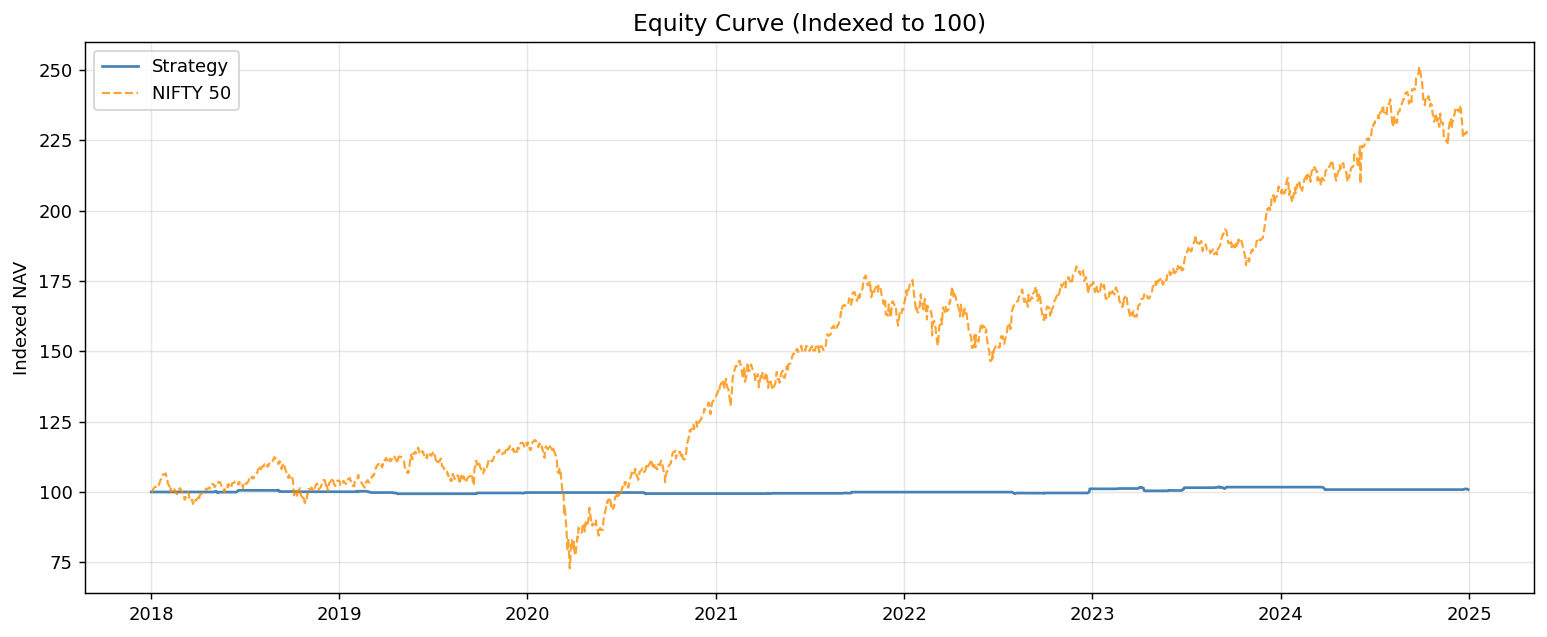

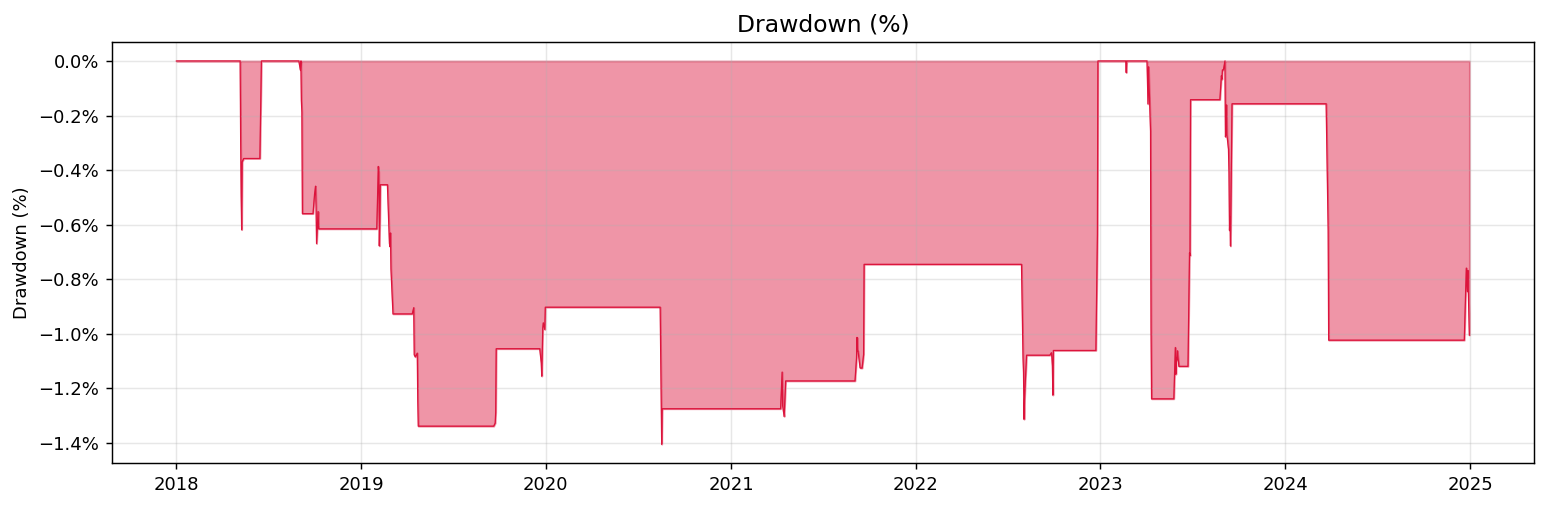

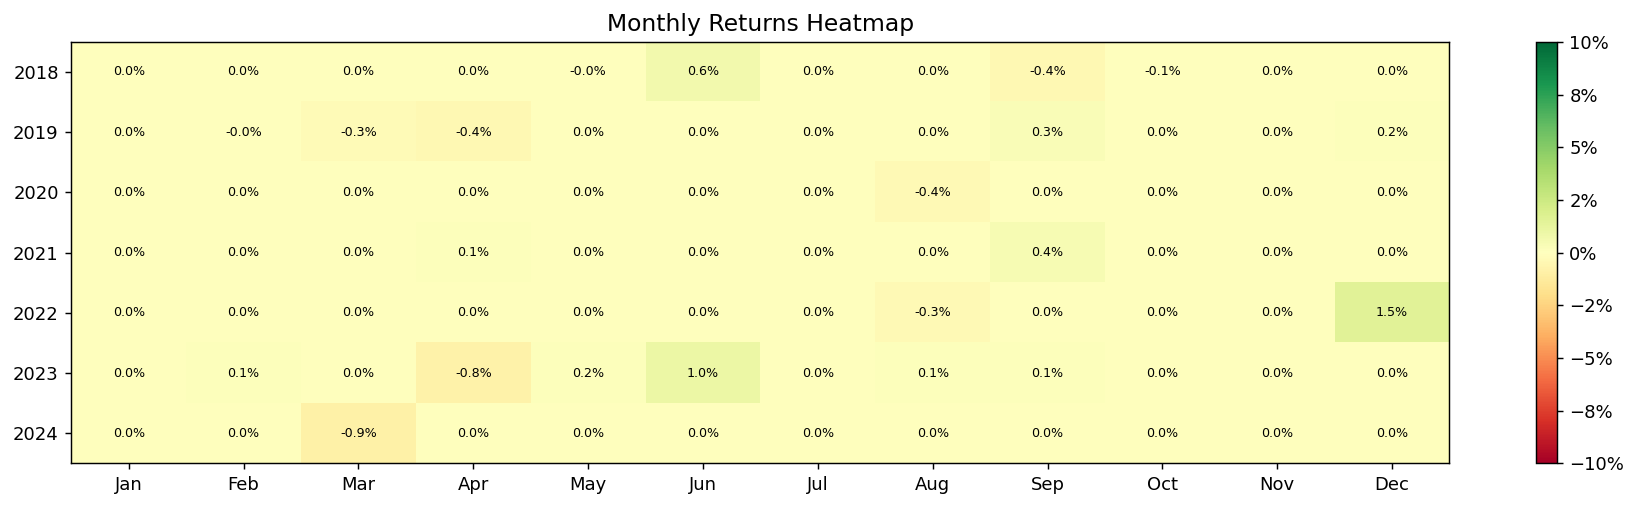

TypeError: NDFrame.fillna() got an unexpected keyword argument 'method'

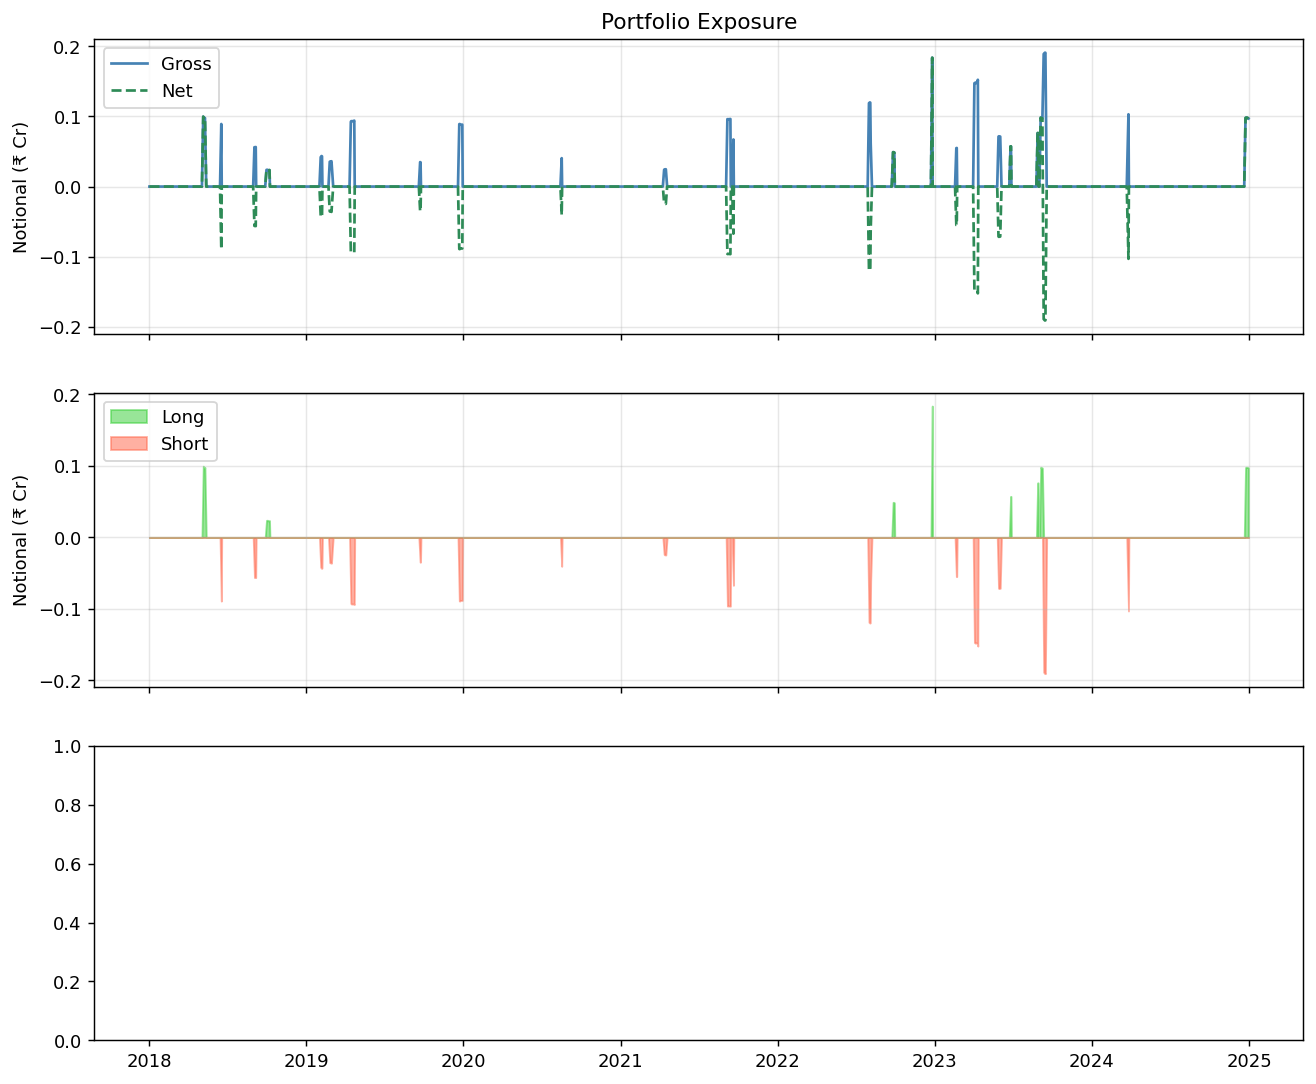

In [16]:
from strategy.metrics import (
    plot_equity_curve, plot_drawdown, plot_monthly_heatmap,
    plot_exposure_analysis, plot_long_short_pnl, plot_rollover_costs,
    plot_stock_contribution, plot_trades_scatter, plot_win_loss_distribution,
)

nifty_spot = dataset['spot']['close'].get('NIFTY')

_ = plot_equity_curve(results['equity_curve'], nifty_spot)
plt.show()

_ = plot_drawdown(results['equity_curve'])
plt.show()

_ = plot_monthly_heatmap(results['daily_returns'])
plt.show()

_ = plot_exposure_analysis(results['exposure_df'], results['equity_curve'])
plt.show()

In [ ]:
if not results['trade_log'].empty:
    _ = plot_long_short_pnl(results['trade_log']); plt.show()
    _ = plot_rollover_costs(results['trade_log']); plt.show()
    _ = plot_stock_contribution(results['trade_log']); plt.show()
    _ = plot_trades_scatter(results['trade_log']); plt.show()
    _ = plot_win_loss_distribution(results['trade_log']); plt.show()

## 10. Trade Log

In [ ]:
tl = results['trade_log']
if not tl.empty:
    display(tl.sort_values('net_pnl').head(10))  # worst 10
    display(tl.sort_values('net_pnl').tail(10))  # best 10
    print('Exit reasons:', tl['exit_reason'].value_counts().to_dict())